# Route Shape vs. Separation: Direction Change Analysis

This notebook investigates how a receiver's **direction change** (the cut) and the **angle of separation** they create drives open space.

### Key Questions
1. How sharp does the cut need to be to create meaningful separation?
2. What separation angle (direction at release vs. nearest defender) best predicts yards of separation?
3. Do larger direction changes lead to more completed passes?

### Methodology
- **Route window**: snap → pass arrives
- **Direction change (cut angle)**: maximum angular change in `dir` within a rolling window during the route
- **Separation**: Euclidean distance between receiver and nearest defender at `pass_arrived`
- **Separation angle**: difference between receiver's `dir` at release and the angle pointing toward the nearest defender

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
import glob
import os

warnings.filterwarnings('ignore')

# ── Style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#1a1a2e',
    'axes.facecolor':   '#16213e',
    'axes.edgecolor':   '#0f3460',
    'axes.labelcolor':  '#e0e0e0',
    'xtick.color':      '#e0e0e0',
    'ytick.color':      '#e0e0e0',
    'text.color':       '#e0e0e0',
    'grid.color':       '#0f3460',
    'grid.alpha':       0.5,
    'font.family':      'sans-serif',
})

OFFENSE_COLOR  = '#e94560'   # red — receiver
DEFENSE_COLOR  = '#0f3460'   # dark blue — defender
ACCENT_COLOR   = '#f5a623'   # gold
COMPLETE_COLOR = '#4caf50'   # green
INCOMPLETE_COLOR = '#ef5350' # red

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data

In [2]:
BASE = 'data'

plays   = pd.read_csv(f'{BASE}/plays.csv')
players = pd.read_csv(f'{BASE}/players.csv')
pff     = pd.read_csv(f'{BASE}/pffScoutingData.csv')

# Load all tracking files
tracking_files = sorted(glob.glob(f'{BASE}/tracking/tracking_*.csv'))
print(f'Loading {len(tracking_files)} tracking files...')
tracking = pd.concat(
    (pd.read_csv(f) for f in tracking_files),
    ignore_index=True
)
print(f'Tracking rows: {len(tracking):,}')
print(f'Plays:   {len(plays):,}')
print(f'Players: {len(players):,}')
print(f'PFF:     {len(pff):,}')

Loading 122 tracking files...
Tracking rows: 8,314,178
Plays:   8,557
Players: 1,679
PFF:     188,254


## 2. Identify Receivers and Pass Plays

In [3]:
# Keep only pass plays with a definitive result (C, I, IN)
pass_plays = plays[
    plays['passResult'].isin(['C', 'I', 'IN'])
][['gameId', 'playId', 'passResult', 'playResult', 'pff_passCoverage', 'pff_passCoverageType']].copy()

# Receivers: pff_role == 'Pass Route'
receivers = pff[
    pff['pff_role'] == 'Pass Route'
][['gameId', 'playId', 'nflId']].copy()
receivers = receivers.merge(pass_plays, on=['gameId', 'playId'])

# Defenders on the same plays
defenders = pff[
    pff['pff_role'].isin(['Coverage', 'Pass Rush'])
][['gameId', 'playId', 'nflId']].copy()
defenders.columns = ['gameId', 'playId', 'def_nflId']

print(f'Pass-route instances: {len(receivers):,}')
print(f'Pass result breakdown:\n{receivers.passResult.value_counts()}')

Pass-route instances: 34,957
Pass result breakdown:
passResult
C     21463
I     12620
IN      874
Name: count, dtype: int64


## 3. Helper Functions

In [4]:
def angular_diff(a, b):
    """Signed angular difference in degrees, accounting for 360° wrap-around."""
    diff = (a - b + 180) % 360 - 180
    return diff


def abs_angular_diff(a, b):
    """Unsigned (absolute) angular difference in degrees, 0–180."""
    return abs(angular_diff(a, b))


def compute_cut_angle(dir_series, window=5):
    """
    Maximum absolute angular change over a rolling `window`-frame span.
    This finds the sharpest single cut in the route.
    """
    dirs = dir_series.values
    max_cut = 0.0
    cut_frame_idx = 0
    for i in range(window, len(dirs)):
        change = abs_angular_diff(dirs[i], dirs[i - window])
        if change > max_cut:
            max_cut = change
            cut_frame_idx = i
    return max_cut, cut_frame_idx


def compute_separation_angle(rec_dir, rec_x, rec_y, def_x, def_y):
    """
    Angle (degrees) between the receiver's direction of motion and
    the vector pointing FROM receiver TO nearest defender.
    A larger angle means the receiver is moving *away* from the defender.
    """
    # Vector from receiver to defender
    dx, dy = def_x - rec_x, def_y - rec_y
    angle_to_def = np.degrees(np.arctan2(dy, dx)) % 360  # 0–360
    return abs_angular_diff(rec_dir, angle_to_def)


print('Helper functions defined.')

Helper functions defined.


## 4. Build Route Metrics Per Receiver Per Play

In [5]:
# Pre-join: attach team info so we can distinguish offense vs defense
tracking_meta = tracking.merge(
    pff[['gameId', 'playId', 'nflId', 'pff_role']],
    on=['gameId', 'playId', 'nflId'],
    how='left'
)

# Focus on the receiver set plays only
rec_set = set(zip(receivers['gameId'], receivers['playId'], receivers['nflId']))

records = []

for (gameId, playId), play_track in tracking.groupby(['gameId', 'playId']):
    if gameId not in plays['gameId'].values:
        continue

    # Events present in this play
    events = play_track[play_track['event'].notna()].set_index('event')

    # We need snap + pass_arrived (or pass_outcome_*) frames
    snap_rows   = play_track[play_track['event'] == 'ball_snap']
    arrive_rows = play_track[
        play_track['event'].isin(['pass_outcome_caught', 'pass_outcome_incomplete',
                                   'pass_outcome_interception', 'pass_arrived'])
    ]

    if snap_rows.empty or arrive_rows.empty:
        continue

    snap_frame   = int(snap_rows['frameId'].iloc[0])
    arrive_frame = int(arrive_rows['frameId'].iloc[0])

    if arrive_frame <= snap_frame:
        continue

    # Defenders in this play (non-football, non-offense)
    play_defenders = play_track[
        (play_track['nflId'].notna()) &
        (play_track['frameId'] == arrive_frame)
    ].copy()

    for nflId in play_track['nflId'].dropna().unique():
        if (gameId, playId, nflId) not in rec_set:
            continue

        # Receiver tracking across the route window
        rec_track = play_track[
            (play_track['nflId'] == nflId) &
            (play_track['frameId'] >= snap_frame) &
            (play_track['frameId'] <= arrive_frame)
        ].sort_values('frameId').copy()

        if len(rec_track) < 6:  # need enough frames for a meaningful cut
            continue

        rec_track = rec_track.dropna(subset=['dir', 'x', 'y', 's'])
        if len(rec_track) < 6:
            continue

        # ── Cut angle: sharpest direction change in the route ──────────────
        cut_angle, cut_frame_idx = compute_cut_angle(rec_track['dir'], window=5)

        # ── Position & direction at pass arrival ───────────────────────────
        rec_at_arrive = rec_track[rec_track['frameId'] == arrive_frame]
        if rec_at_arrive.empty:
            rec_at_arrive = rec_track.iloc[[-1]]

        rec_x   = float(rec_at_arrive['x'].iloc[0])
        rec_y   = float(rec_at_arrive['y'].iloc[0])
        rec_dir = float(rec_at_arrive['dir'].iloc[0])
        rec_spd = float(rec_at_arrive['s'].iloc[0])

        # ── Nearest defender at pass arrival ──────────────────────────────
        # Defenders = players on the opposing team at that frame
        rec_team = str(rec_at_arrive['team'].iloc[0])
        defs_at_arrive = play_defenders[
            (play_defenders['team'] != rec_team) &
            (play_defenders['team'] != 'football') &
            (play_defenders['nflId'] != nflId)
        ].copy()

        if defs_at_arrive.empty:
            continue

        defs_at_arrive['dist'] = np.sqrt(
            (defs_at_arrive['x'] - rec_x)**2 +
            (defs_at_arrive['y'] - rec_y)**2
        )
        nearest = defs_at_arrive.loc[defs_at_arrive['dist'].idxmin()]
        separation = float(nearest['dist'])

        # ── Separation angle ───────────────────────────────────────────────
        sep_angle = compute_separation_angle(
            rec_dir, rec_x, rec_y,
            float(nearest['x']), float(nearest['y'])
        )

        # ── Direction change leading into the cut ──────────────────────────
        # Pre-cut direction (avg over 5 frames before the cut)
        cut_abs_frame = int(rec_track.iloc[cut_frame_idx]['frameId']) if cut_frame_idx < len(rec_track) else snap_frame
        pre_cut = rec_track[rec_track['frameId'] < cut_abs_frame].tail(5)
        post_cut = rec_track[rec_track['frameId'] >= cut_abs_frame].head(5)

        pre_dir  = float(pre_cut['dir'].mean())  if len(pre_cut)  >= 2 else np.nan
        post_dir = float(post_cut['dir'].mean()) if len(post_cut) >= 2 else np.nan
        speed_at_cut = float(rec_track.iloc[min(cut_frame_idx, len(rec_track)-1)]['s'])

        # Route length
        route_frames = arrive_frame - snap_frame

        records.append({
            'gameId':          gameId,
            'playId':          playId,
            'nflId':           nflId,
            'cut_angle':       cut_angle,
            'pre_cut_dir':     pre_dir,
            'post_cut_dir':    post_dir,
            'speed_at_cut':    speed_at_cut,
            'separation':      separation,
            'sep_angle':       sep_angle,
            'rec_dir_arrive':  rec_dir,
            'rec_speed_arrive':rec_spd,
            'route_frames':    route_frames,
        })

metrics = pd.DataFrame(records)
metrics = metrics.merge(receivers[['gameId','playId','nflId','passResult','playResult','pff_passCoverage','pff_passCoverageType']], on=['gameId','playId','nflId'])
metrics = metrics.merge(players[['nflId','displayName','officialPosition']], on='nflId', how='left')

print(f'Route-level metrics computed: {len(metrics):,} routes')
metrics.head(3)

Route-level metrics computed: 2,019 routes


,gameId,playId,nflId,cut_angle,pre_cut_dir,post_cut_dir,speed_at_cut,separation,sep_angle,rec_dir_arrive,rec_speed_arrive,route_frames,passResult,playResult,pff_passCoverage,pff_passCoverageType,displayName,officialPosition
0,2021090900,410,35481.0,31.74,101.562,NaN,4.64,1.220369,66.339421,123.04,4.64,21,C,10,Cover-1,Man,Rob Gronkowski,TE
1,2021090900,410,35634.0,71.78,83.406,63.932,1.51,0.972934,150.135067,72.60,7.13,21,C,10,Cover-1,Man,Antonio Brown,WR
2,2021090900,410,41233.0,32.99,111.766,135.576,6.02,2.586600,110.624183,139.27,6.77,21,C,10,Cover-1,Man,Mike Evans,WR


## 5. Cut Angle Distribution

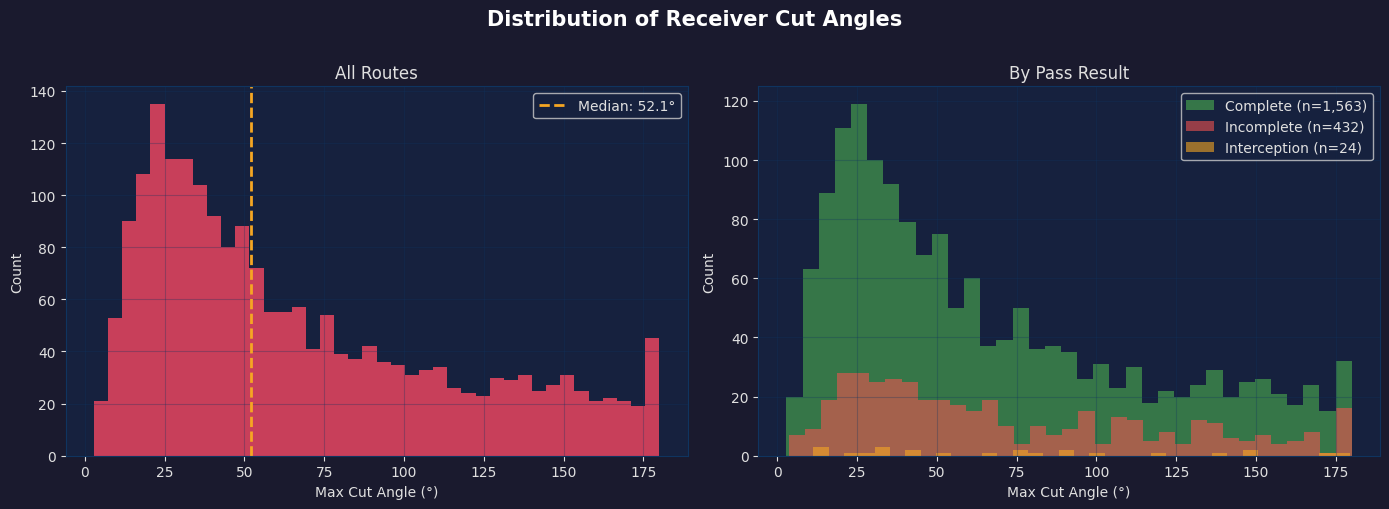

Saved: cut_angle_distribution.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution of Receiver Cut Angles', fontsize=15, fontweight='bold', color='white', y=1.01)

# ── Left: overall distribution ─────────────────────────────────────────────
ax = axes[0]
ax.hist(metrics['cut_angle'], bins=40, color=OFFENSE_COLOR, alpha=0.85, edgecolor='none')
ax.axvline(metrics['cut_angle'].median(), color=ACCENT_COLOR, lw=2, linestyle='--',
           label=f"Median: {metrics['cut_angle'].median():.1f}°")
ax.set_xlabel('Max Cut Angle (°)')
ax.set_ylabel('Count')
ax.set_title('All Routes')
ax.legend()
ax.grid(True, alpha=0.3)

# ── Right: by pass result ──────────────────────────────────────────────────
ax = axes[1]
colors = {'C': COMPLETE_COLOR, 'I': INCOMPLETE_COLOR, 'IN': ACCENT_COLOR}
labels = {'C': 'Complete', 'I': 'Incomplete', 'IN': 'Interception'}
for result, grp in metrics.groupby('passResult'):
    ax.hist(grp['cut_angle'], bins=35, alpha=0.6,
            color=colors.get(result, 'gray'),
            label=f"{labels.get(result, result)} (n={len(grp):,})",
            edgecolor='none')
ax.set_xlabel('Max Cut Angle (°)')
ax.set_ylabel('Count')
ax.set_title('By Pass Result')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cut_angle_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cut_angle_distribution.png')

## 6. Cut Angle vs. Separation — Core Scatter

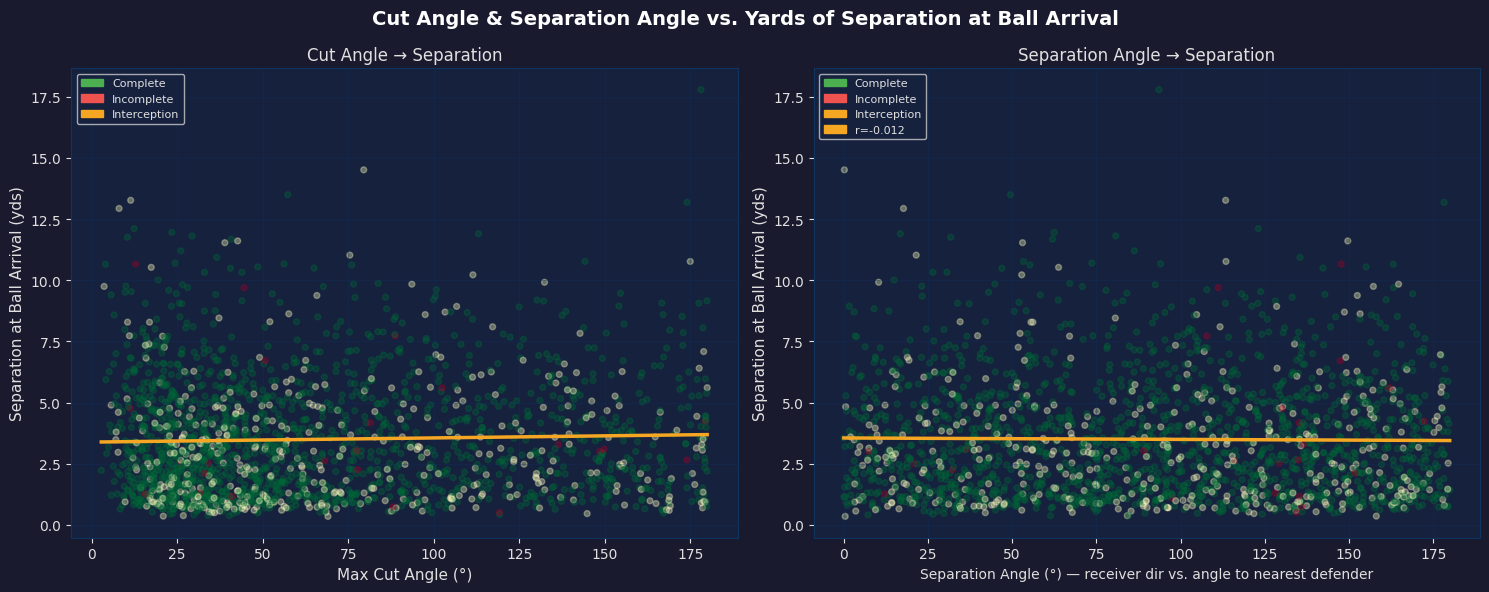

Saved: cut_vs_separation_scatter.png


In [7]:
clean = metrics.dropna(subset=['cut_angle', 'separation', 'sep_angle'])
clean = clean[clean['separation'] < 25]  # remove extreme outliers

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Cut Angle & Separation Angle vs. Yards of Separation at Ball Arrival',
             fontsize=14, fontweight='bold', color='white')

# ── Left: Cut angle vs separation ─────────────────────────────────────────
ax = axes[0]
sc = ax.scatter(
    clean['cut_angle'], clean['separation'],
    c=clean['passResult'].map({'C': 1, 'I': 0, 'IN': -1}),
    cmap='RdYlGn', alpha=0.35, s=18, vmin=-1, vmax=1
)

# Regression line
slope, intercept, r, p, se = stats.linregress(clean['cut_angle'], clean['separation'])
x_line = np.linspace(clean['cut_angle'].min(), clean['cut_angle'].max(), 200)
ax.plot(x_line, slope * x_line + intercept, color=ACCENT_COLOR, lw=2.5,
        label=f'r={r:.3f}, p={p:.4f}')

ax.set_xlabel('Max Cut Angle (°)', fontsize=11)
ax.set_ylabel('Separation at Ball Arrival (yds)', fontsize=11)
ax.set_title('Cut Angle → Separation')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

patches = [
    mpatches.Patch(color=COMPLETE_COLOR,  label='Complete'),
    mpatches.Patch(color=INCOMPLETE_COLOR, label='Incomplete'),
    mpatches.Patch(color=ACCENT_COLOR,     label='Interception'),
]
ax.legend(handles=patches, loc='upper left', fontsize=8)

# ── Right: Sep angle vs separation ────────────────────────────────────────
ax = axes[1]
ax.scatter(
    clean['sep_angle'], clean['separation'],
    c=clean['passResult'].map({'C': 1, 'I': 0, 'IN': -1}),
    cmap='RdYlGn', alpha=0.35, s=18, vmin=-1, vmax=1
)

slope2, intercept2, r2, p2, _ = stats.linregress(clean['sep_angle'], clean['separation'])
x_line2 = np.linspace(clean['sep_angle'].min(), clean['sep_angle'].max(), 200)
ax.plot(x_line2, slope2 * x_line2 + intercept2, color=ACCENT_COLOR, lw=2.5,
        label=f'r={r2:.3f}, p={p2:.4f}')

ax.set_xlabel('Separation Angle (°) — receiver dir vs. angle to nearest defender', fontsize=10)
ax.set_ylabel('Separation at Ball Arrival (yds)', fontsize=11)
ax.set_title('Separation Angle → Separation')
ax.legend(handles=patches + [mpatches.Patch(color=ACCENT_COLOR, label=f'r={r2:.3f}')], loc='upper left', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cut_vs_separation_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cut_vs_separation_scatter.png')

## 7. Separation by Cut Angle Bucket

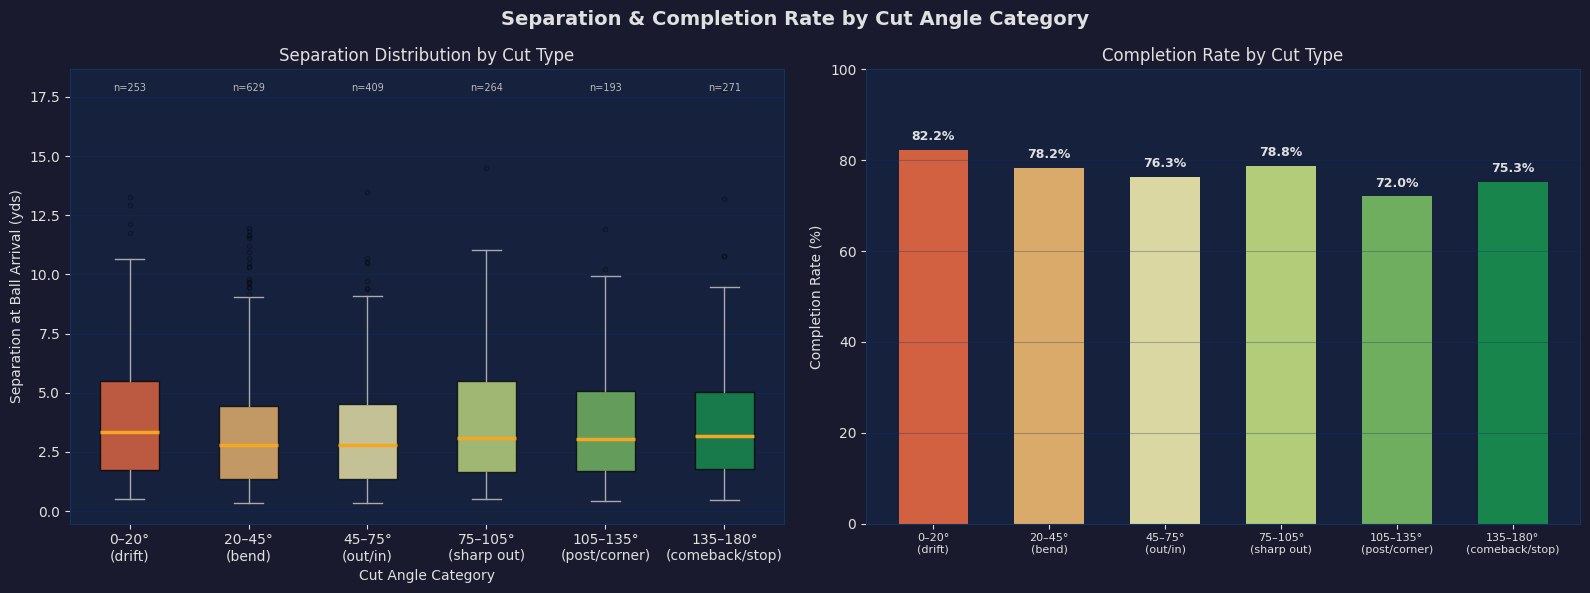

Saved: separation_by_cut_bucket.png


In [8]:
bins   = [0, 20, 45, 75, 105, 135, 180]
labels_cut = ['0–20°\n(drift)', '20–45°\n(bend)', '45–75°\n(out/in)', 
               '75–105°\n(sharp out)', '105–135°\n(post/corner)', '135–180°\n(comeback/stop)']

clean['cut_bucket'] = pd.cut(clean['cut_angle'], bins=bins, labels=labels_cut)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Separation & Completion Rate by Cut Angle Category', fontsize=14, fontweight='bold')

# ── Left: separation boxplot by cut bucket ────────────────────────────────
ax = axes[0]
bucket_groups = [clean[clean['cut_bucket'] == b]['separation'].dropna().values
                 for b in labels_cut]
bp = ax.boxplot(bucket_groups, labels=labels_cut, patch_artist=True, notch=False,
                medianprops=dict(color=ACCENT_COLOR, linewidth=2.5),
                whiskerprops=dict(color='#aaa'),
                capprops=dict(color='#aaa'),
                flierprops=dict(marker='o', color='#aaa', alpha=0.3, markersize=3))

palette = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(labels_cut)))
for patch, color in zip(bp['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xlabel('Cut Angle Category')
ax.set_ylabel('Separation at Ball Arrival (yds)')
ax.set_title('Separation Distribution by Cut Type')
ax.grid(True, alpha=0.3, axis='y')

# Add sample sizes
for i, lbl in enumerate(labels_cut):
    n = len(bucket_groups[i])
    ax.text(i + 1, ax.get_ylim()[1] * 0.97, f'n={n}', ha='center', va='top', fontsize=7, color='#bbb')

# ── Right: completion rate by cut bucket ──────────────────────────────────
ax = axes[1]
comp_rates = (
    clean.groupby('cut_bucket')['passResult']
    .apply(lambda x: (x == 'C').mean() * 100)
    .reindex(labels_cut)
)
counts = clean.groupby('cut_bucket').size().reindex(labels_cut)

bars = ax.bar(range(len(labels_cut)), comp_rates.values, color=palette, alpha=0.85, width=0.6)
ax.set_xticks(range(len(labels_cut)))
ax.set_xticklabels(labels_cut, fontsize=8)
ax.set_ylabel('Completion Rate (%)')
ax.set_title('Completion Rate by Cut Type')
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, axis='y')

for bar, rate in zip(bars, comp_rates.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{rate:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('separation_by_cut_bucket.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: separation_by_cut_bucket.png')

## 8. Speed at Cut vs. Separation

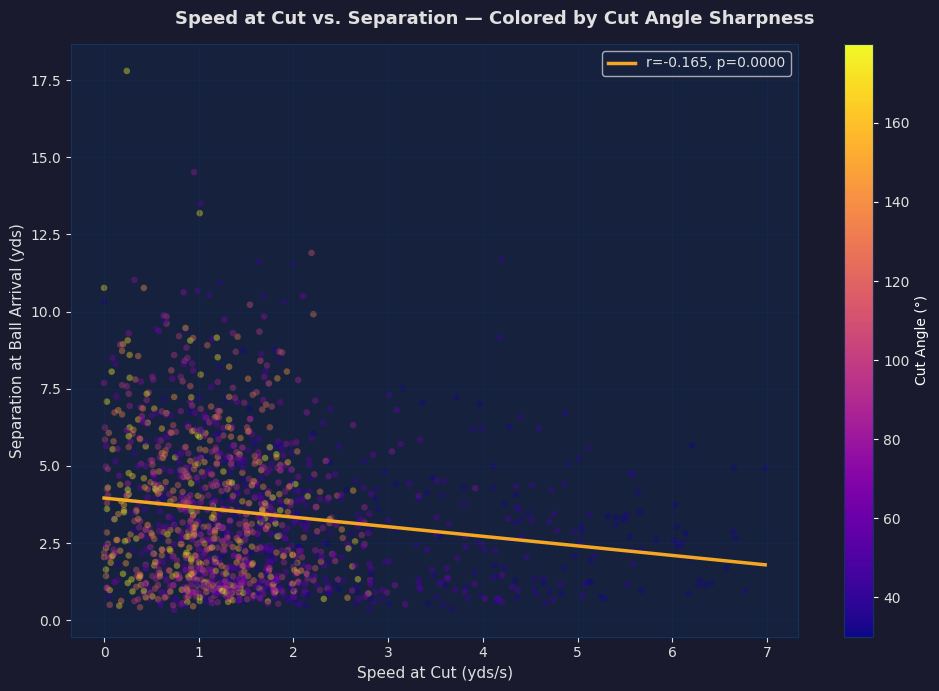

Saved: speed_at_cut_vs_separation.png


In [9]:
"""Does a faster cut (high speed, sharp angle) produce more separation?"""

clean_cut = clean[clean['cut_angle'] > 30].copy()  # only meaningful cuts

fig, ax = plt.subplots(figsize=(10, 7))
fig.suptitle('Speed at Cut vs. Separation — Colored by Cut Angle Sharpness',
             fontsize=13, fontweight='bold')

norm = Normalize(vmin=clean_cut['cut_angle'].min(), vmax=clean_cut['cut_angle'].max())
cmap = plt.cm.plasma

sc = ax.scatter(
    clean_cut['speed_at_cut'], clean_cut['separation'],
    c=clean_cut['cut_angle'], cmap=cmap, norm=norm,
    alpha=0.4, s=22, edgecolors='none'
)

cbar = plt.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cbar.set_label('Cut Angle (°)', color='white')
cbar.ax.yaxis.set_tick_params(color='white')

# Regression
slope_s, intercept_s, r_s, p_s, _ = stats.linregress(
    clean_cut['speed_at_cut'], clean_cut['separation'])
x_spd = np.linspace(clean_cut['speed_at_cut'].min(), clean_cut['speed_at_cut'].max(), 200)
ax.plot(x_spd, slope_s * x_spd + intercept_s, color=ACCENT_COLOR, lw=2.5,
        label=f'r={r_s:.3f}, p={p_s:.4f}')

ax.set_xlabel('Speed at Cut (yds/s)', fontsize=11)
ax.set_ylabel('Separation at Ball Arrival (yds)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('speed_at_cut_vs_separation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: speed_at_cut_vs_separation.png')

## 9. Single-Route Visualizer: Direction Arrow Heatmap

Plotting route with largest cut angle: Hayden Hurst, cut=180.0°, sep=2.2 yds


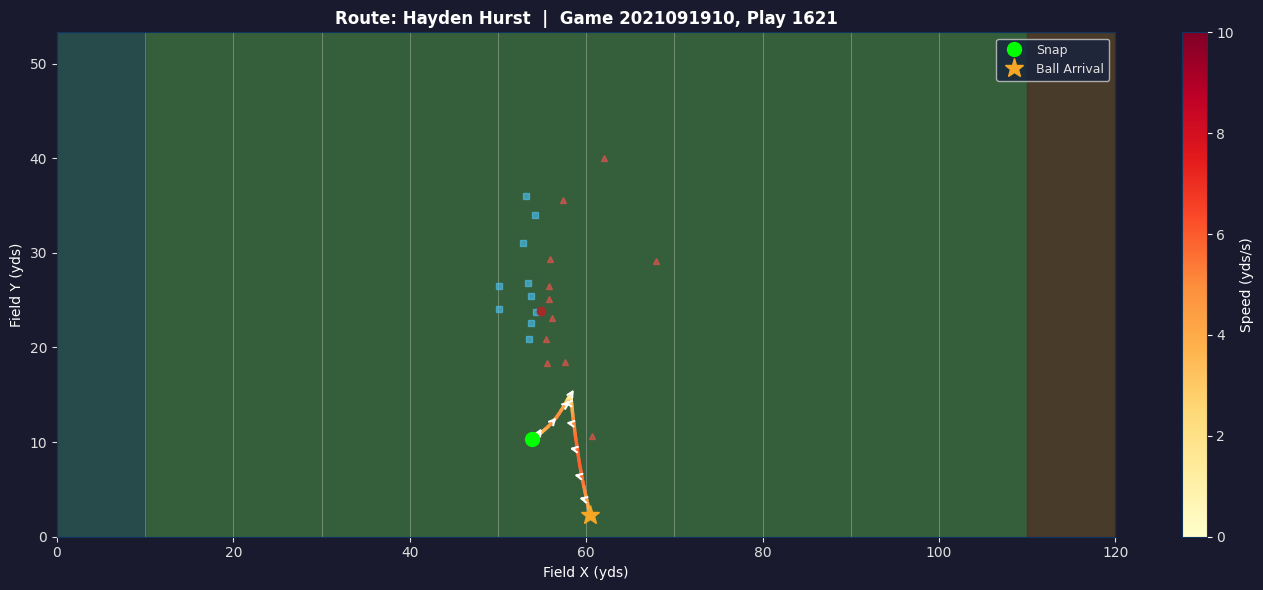

In [10]:
def draw_field_backdrop(ax, x_range=(0, 120), y_range=(0, 53.3)):
    """Draw a minimal NFL field backdrop."""
    ax.set_facecolor('#355E3B')  # grass green
    ax.set_xlim(x_range)
    ax.set_ylim(y_range)
    # Yard lines every 10 yards
    for x in range(10, 110, 10):
        ax.axvline(x, color='white', lw=0.4, alpha=0.5)
    # End zones
    ax.axvspan(0,  10, color='#1a3a5c', alpha=0.5)
    ax.axvspan(110, 120, color='#5c1a1a', alpha=0.5)
    ax.set_xlabel('Field X (yds)', color='white')
    ax.set_ylabel('Field Y (yds)', color='white')


def plot_route_with_direction(gameId, playId, nflId, tracking_df, pff_df):
    """Plot a single receiver's route with direction arrows and color-coded speed."""
    play_track = tracking_df[
        (tracking_df['gameId'] == gameId) &
        (tracking_df['playId'] == playId)
    ].copy()

    snap_frame   = int(play_track[play_track['event'] == 'ball_snap']['frameId'].iloc[0])
    arrive_rows  = play_track[
        play_track['event'].isin(['pass_outcome_caught', 'pass_outcome_incomplete',
                                   'pass_outcome_interception', 'pass_arrived'])]
    arrive_frame = int(arrive_rows['frameId'].iloc[0]) if not arrive_rows.empty else play_track['frameId'].max()

    rec_track = play_track[
        (play_track['nflId'] == nflId) &
        (play_track['frameId'] >= snap_frame) &
        (play_track['frameId'] <= arrive_frame)
    ].sort_values('frameId').dropna(subset=['x', 'y', 'dir', 's'])

    if len(rec_track) < 3:
        print('Not enough frames.')
        return

    # All other players at snap
    others = play_track[play_track['frameId'] == snap_frame]

    fig, ax = plt.subplots(figsize=(14, 6))
    draw_field_backdrop(ax)

    # Plot all other players
    rec_team = str(rec_track['team'].iloc[0])
    for _, row in others.iterrows():
        if row['nflId'] == nflId:
            continue
        if row['team'] == 'football':
            ax.plot(row['x'], row['y'], 'o', color='brown', ms=6, zorder=5)
        elif row['team'] == rec_team:
            ax.plot(row['x'], row['y'], 's', color='#4fc3f7', ms=5, alpha=0.6, zorder=4)
        else:
            ax.plot(row['x'], row['y'], '^', color='#ef5350', ms=5, alpha=0.6, zorder=4)

    # Route path colored by speed
    xs, ys, spds = rec_track['x'].values, rec_track['y'].values, rec_track['s'].values
    norm = Normalize(vmin=0, vmax=10)
    cmap = plt.cm.YlOrRd
    for i in range(len(xs) - 1):
        ax.plot([xs[i], xs[i+1]], [ys[i], ys[i+1]],
                color=cmap(norm(spds[i])), lw=2.5, solid_capstyle='round')

    # Direction arrows every 5 frames
    for i in range(0, len(rec_track), 5):
        row = rec_track.iloc[i]
        # dir=0° is East in the data (degrees measured from +x axis)
        rad = np.radians(row['dir'])
        dx_arr = np.cos(rad) * 1.2
        dy_arr = np.sin(rad) * 1.2
        ax.annotate('', xy=(row['x'] + dx_arr, row['y'] + dy_arr),
                    xytext=(row['x'], row['y']),
                    arrowprops=dict(arrowstyle='->', color='white', lw=1.5))

    # Mark snap and arrival
    ax.plot(xs[0], ys[0], 'o', color='lime', ms=10, zorder=10, label='Snap')
    ax.plot(xs[-1], ys[-1], '*', color=ACCENT_COLOR, ms=14, zorder=10, label='Ball Arrival')

    cbar = plt.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax)
    cbar.set_label('Speed (yds/s)', color='white')
    cbar.ax.yaxis.set_tick_params(color='white')

    name = players[players['nflId'] == nflId]['displayName'].values
    name = name[0] if len(name) else str(nflId)
    ax.set_title(f'Route: {name}  |  Game {gameId}, Play {playId}',
                 fontsize=12, fontweight='bold', color='white')
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.savefig(f'route_{gameId}_{playId}_{int(nflId)}.png', dpi=150, bbox_inches='tight')
    plt.show()


# ── Example: pick the route with the largest cut angle ────────────────────
best_cut = metrics.sort_values('cut_angle', ascending=False).iloc[0]
print(f"Plotting route with largest cut angle: {best_cut['displayName']}, "
      f"cut={best_cut['cut_angle']:.1f}°, sep={best_cut['separation']:.1f} yds")
plot_route_with_direction(
    int(best_cut['gameId']), int(best_cut['playId']), int(best_cut['nflId']),
    tracking, pff
)

## 10. Polar Plot — Direction Change Profile

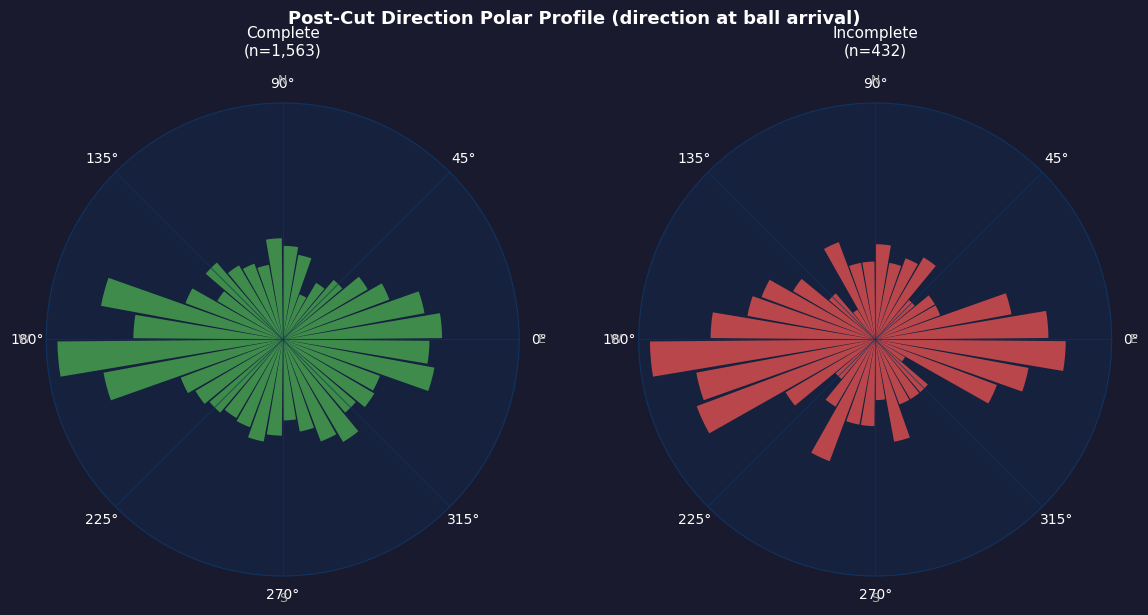

Saved: polar_direction_profile.png


In [11]:
"""
Polar histogram: what direction does the receiver move AFTER their sharpest cut?
Shows the dominant break directions for completed vs. incomplete passes.
"""
fig, axes = plt.subplots(1, 2, figsize=(12, 6),
                          subplot_kw={'projection': 'polar'})
fig.patch.set_facecolor('#1a1a2e')
fig.suptitle('Post-Cut Direction Polar Profile (direction at ball arrival)',
             fontsize=13, fontweight='bold', color='white')

result_map = {'C': (0, 'Complete', COMPLETE_COLOR),
              'I': (1, 'Incomplete', INCOMPLETE_COLOR)}

for result, (idx, label, color) in result_map.items():
    ax = axes[idx]
    ax.set_facecolor('#16213e')

    subset = clean[clean['passResult'] == result]['rec_dir_arrive'].dropna()
    # Convert to radians
    theta = np.radians(subset.values)
    n_bins = 36  # 10° per bin
    counts_arr, bin_edges = np.histogram(theta, bins=np.linspace(0, 2*np.pi, n_bins + 1))
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    width = 2 * np.pi / n_bins

    bars = ax.bar(bin_centers, counts_arr, width=width * 0.9,
                  color=color, alpha=0.75, edgecolor='none')

    ax.set_title(f'{label}\n(n={len(subset):,})', color='white', pad=15, fontsize=11)
    ax.tick_params(colors='white')
    ax.set_theta_zero_location('E')   # 0° = East (right)
    ax.set_theta_direction(1)          # counter-clockwise
    ax.set_yticks([])
    ax.grid(color='#0f3460', alpha=0.6)

    # Label cardinal directions
    for ang, lbl in [(0, 'E'), (np.pi/2, 'N'), (np.pi, 'W'), (3*np.pi/2, 'S')]:
        ax.text(ang, counts_arr.max() * 1.15, lbl,
                ha='center', va='center', color='#aaa', fontsize=9)

plt.tight_layout()
plt.savefig('polar_direction_profile.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: polar_direction_profile.png')

## 11. Top Receivers by Avg Separation — Cut Angle Profile

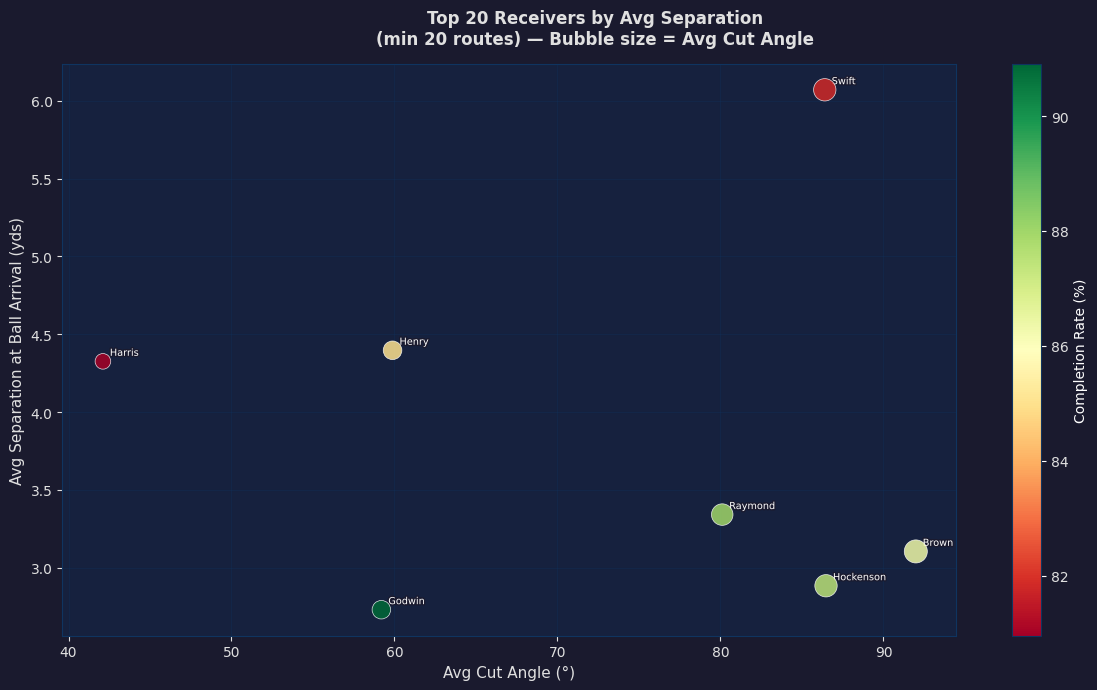

      displayName officialPosition  routes  avg_separation  avg_cut_angle  avg_sep_angle  comp_rate
    D'Andre Swift               RB      22        6.069818      86.399091      87.909981  81.818182
    Derrick Henry               RB      20        4.396965      59.880500      98.791377  85.000000
     Najee Harris               RB      21        4.325940      42.111429      78.381767  80.952381
    Kalif Raymond               WR      25        3.341940      80.108000      96.408445  88.000000
Amon-Ra St. Brown               WR      22        3.105377      91.985000      93.675886  86.363636
   T.J. Hockenson               TE      24        2.884909      86.475000     100.364419  87.500000
     Chris Godwin               WR      22        2.731115      59.195000      91.402194  90.909091
Saved: top_receivers_cut_vs_separation.png


In [12]:
"""Which receivers generate the most separation and how do their cut angles compare?"""

MIN_ROUTES = 20  # minimum routes to qualify

player_stats = (
    clean.groupby(['nflId', 'displayName', 'officialPosition'])
    .agg(
        routes=('cut_angle', 'count'),
        avg_separation=('separation', 'mean'),
        avg_cut_angle=('cut_angle', 'mean'),
        avg_sep_angle=('sep_angle', 'mean'),
        comp_rate=('passResult', lambda x: (x == 'C').mean() * 100),
    )
    .reset_index()
    .query(f'routes >= {MIN_ROUTES}')
    .sort_values('avg_separation', ascending=False)
)

top_n = 20
top_players = player_stats.head(top_n)

fig, ax = plt.subplots(figsize=(12, 7))
fig.suptitle(f'Top {top_n} Receivers by Avg Separation\n'
             f'(min {MIN_ROUTES} routes) — Bubble size = Avg Cut Angle',
             fontsize=12, fontweight='bold')

norm = Normalize(vmin=top_players['comp_rate'].min(), vmax=top_players['comp_rate'].max())
cmap = plt.cm.RdYlGn

scatter = ax.scatter(
    top_players['avg_cut_angle'],
    top_players['avg_separation'],
    s=top_players['avg_cut_angle'] * 3,
    c=top_players['comp_rate'],
    cmap=cmap, norm=norm,
    alpha=0.85, edgecolors='white', linewidth=0.5, zorder=5
)

cbar = plt.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cbar.set_label('Completion Rate (%)', color='white')
cbar.ax.yaxis.set_tick_params(color='white')

for _, row in top_players.iterrows():
    ax.annotate(
        row['displayName'].split(' ')[-1],  # last name only
        (row['avg_cut_angle'], row['avg_separation']),
        textcoords='offset points', xytext=(5, 4),
        fontsize=7, color='white',
        path_effects=[pe.withStroke(linewidth=2, foreground='#1a1a2e')]
    )

ax.set_xlabel('Avg Cut Angle (°)', fontsize=11)
ax.set_ylabel('Avg Separation at Ball Arrival (yds)', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('top_receivers_cut_vs_separation.png', dpi=150, bbox_inches='tight')
plt.show()
print(top_players[['displayName', 'officialPosition', 'routes', 'avg_separation',
                    'avg_cut_angle', 'avg_sep_angle', 'comp_rate']].to_string(index=False))
print('Saved: top_receivers_cut_vs_separation.png')

## 12. Separation Angle vs. Separation — by Coverage Type

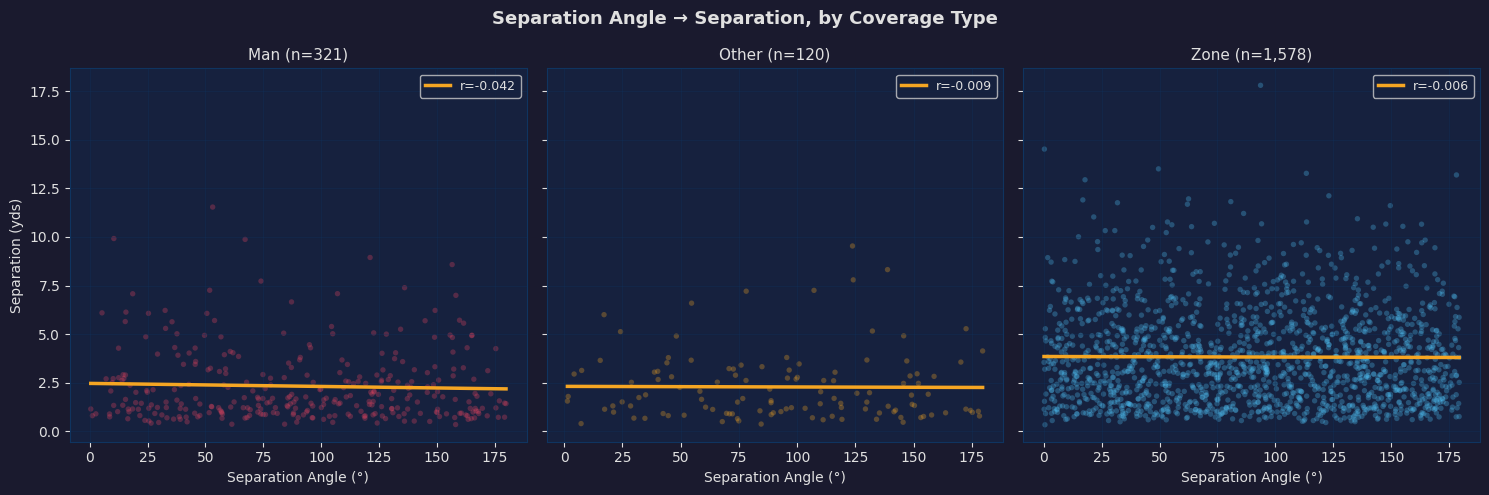

Saved: sep_angle_by_coverage.png


In [13]:
"""Does the coverage type change how important the separation angle is?"""

coverage_types = clean['pff_passCoverageType'].dropna().unique()
fig, axes = plt.subplots(1, len(coverage_types), figsize=(5 * len(coverage_types), 5), sharey=True)
fig.suptitle('Separation Angle → Separation, by Coverage Type', fontsize=13, fontweight='bold')

if len(coverage_types) == 1:
    axes = [axes]

coverage_colors = {'Man': '#e94560', 'Zone': '#4fc3f7', 'Other': '#f5a623'}

for ax, cov in zip(axes, sorted(coverage_types)):
    subset = clean[clean['pff_passCoverageType'] == cov]
    ax.scatter(subset['sep_angle'], subset['separation'],
               color=coverage_colors.get(cov, 'gray'), alpha=0.3, s=15, edgecolors='none')

    if len(subset) > 5:
        slope_c, intercept_c, r_c, p_c, _ = stats.linregress(
            subset['sep_angle'], subset['separation'])
        x_c = np.linspace(subset['sep_angle'].min(), subset['sep_angle'].max(), 200)
        ax.plot(x_c, slope_c * x_c + intercept_c,
                color=ACCENT_COLOR, lw=2.5, label=f'r={r_c:.3f}')
        ax.legend(fontsize=9)

    ax.set_title(f'{cov} (n={len(subset):,})', fontsize=11)
    ax.set_xlabel('Separation Angle (°)')
    if ax == axes[0]:
        ax.set_ylabel('Separation (yds)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sep_angle_by_coverage.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: sep_angle_by_coverage.png')

## 13. Summary Statistics

In [14]:
print('=== Route Shape vs. Separation — Summary ===')
print(f'Total routes analyzed: {len(clean):,}')
print()

print('── Cut Angle (°) ──')
print(clean['cut_angle'].describe().round(2))
print()

print('── Separation at Ball Arrival (yds) ──')
print(clean['separation'].describe().round(2))
print()

print('── Separation Angle (°) ──')
print(clean['sep_angle'].describe().round(2))
print()

print('── Avg Separation by Pass Result ──')
print(clean.groupby('passResult')['separation'].mean().round(2))
print()

print('── Avg Cut Angle by Pass Result ──')
print(clean.groupby('passResult')['cut_angle'].mean().round(2))
print()

# Pearson correlations
print('── Pearson Correlations with Separation ──')
for col in ['cut_angle', 'sep_angle', 'speed_at_cut']:
    r, p = stats.pearsonr(clean[col].dropna(), clean.loc[clean[col].notna(), 'separation'])
    print(f'  {col:20s}  r={r:+.4f}  p={p:.4e}')

=== Route Shape vs. Separation — Summary ===
Total routes analyzed: 2,019

── Cut Angle (°) ──
count    2019.00
mean       67.60
std        47.63
min         2.85
25%        28.66
50%        52.12
75%        99.09
max       179.97
Name: cut_angle, dtype: float64

── Separation at Ball Arrival (yds) ──
count    2019.00
mean        3.50
std         2.40
min         0.34
25%         1.52
50%         2.97
75%         4.89
max        17.79
Name: separation, dtype: float64

── Separation Angle (°) ──
count    2019.00
mean       91.48
std        50.73
min         0.07
25%        47.51
50%        92.73
75%       135.26
max       179.87
Name: sep_angle, dtype: float64

── Avg Separation by Pass Result ──
passResult
C     3.58
I     3.19
IN    3.61
Name: separation, dtype: float64

── Avg Cut Angle by Pass Result ──
passResult
C     66.27
I     72.00
IN    75.66
Name: cut_angle, dtype: float64

── Pearson Correlations with Separation ──
  cut_angle             r=+0.0338  p=1.2839e-01
  sep_angle